In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [2]:
caminho = Path.cwd().resolve().parent / "data" / "processed" / "incidentes_tratados.csv"

dados = pd.read_csv(caminho, encoding="utf-8-sig", parse_dates=["Data"])

dados.head()


,Ano,Mes,Total,Worm,DOS,Invasao,Web,Scan,Fraude,Outros,Numero_Mes,Data
0,2010,Janeiro,8223,1467,5,1,402,3042,2545,761,1,2010-01-01
1,2010,Fevereiro,8266,2170,5,5,470,2920,2313,383,2,2010-02-01
2,2010,Março,11836,2236,0,1,780,4573,3529,717,3,2010-03-01
3,2010,Abril,11462,2127,0,3,522,5463,2829,518,4,2010-04-01
4,2010,Maio,9680,1310,3,7,653,5027,2359,321,5,2010-05-01


Total de incidentes por ano:
Ano
2010     142844
2011     399515
2012     466029
2013     352925
2014    1047031
2015     722205
2016     647112
2017     833775
2018     676514
2019     875327
Name: Total, dtype: int64


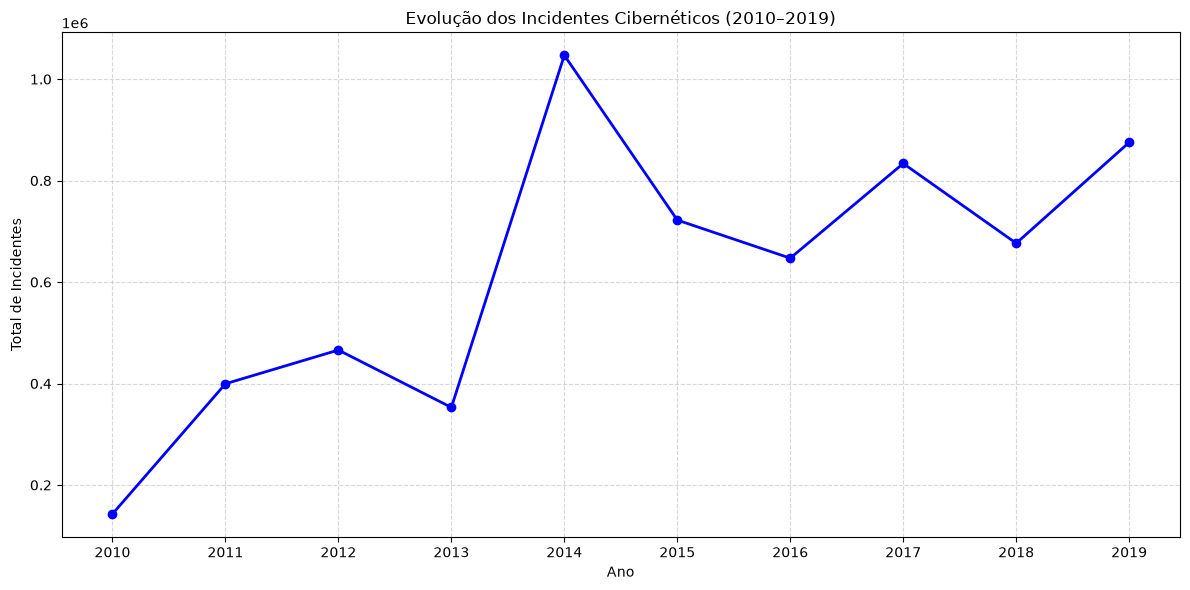

In [4]:
incidentes_anuais = dados.groupby("Ano")["Total"].sum()

print("Total de incidentes por ano:")
print(incidentes_anuais)

plt.figure(figsize=(12, 6))

plt.plot(
    incidentes_anuais.index,
    incidentes_anuais.values,
    marker="o",
    linewidth=2,
    color="blue"
)

plt.title("Evolução dos Incidentes Cibernéticos (2010–2019)")
plt.xlabel("Ano")
plt.ylabel("Total de Incidentes")

plt.xticks(incidentes_anuais.index)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Total de incidentes por categoria:
Scan       2887799
Fraude     1102161
DOS         991439
Worm        413780
Outros      393547
Web         342670
Invasao      31881
dtype: int64


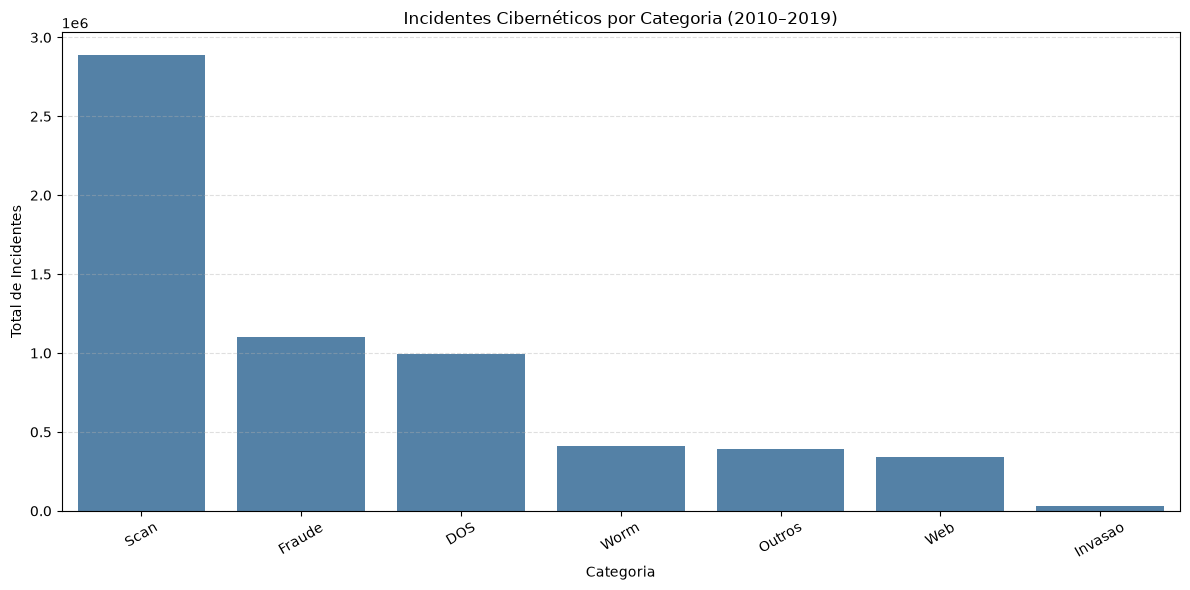

In [5]:
categorias = [
    "Worm",
    "DOS",
    "Invasao",
    "Web",
    "Scan",
    "Fraude",
    "Outros"
]

total_categorias = dados[categorias].sum()

total_categorias = total_categorias.sort_values(ascending=False)

print("Total de incidentes por categoria:")
print(total_categorias)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=total_categorias.index,
    y=total_categorias.values,
    color="steelblue"
)

plt.title("Incidentes Cibernéticos por Categoria (2010–2019)")
plt.xlabel("Categoria")
plt.ylabel("Total de Incidentes")

plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Variação percentual anual dos incidentes:
Ano
2011    179.69
2012     16.65
2013    -24.27
2014    196.67
2015    -31.02
2016    -10.40
2017     28.85
2018    -18.86
2019     29.39
Name: Total, dtype: float64

Maior aumento:
2014: 196.67%

Maior redução:
2015: -31.02%


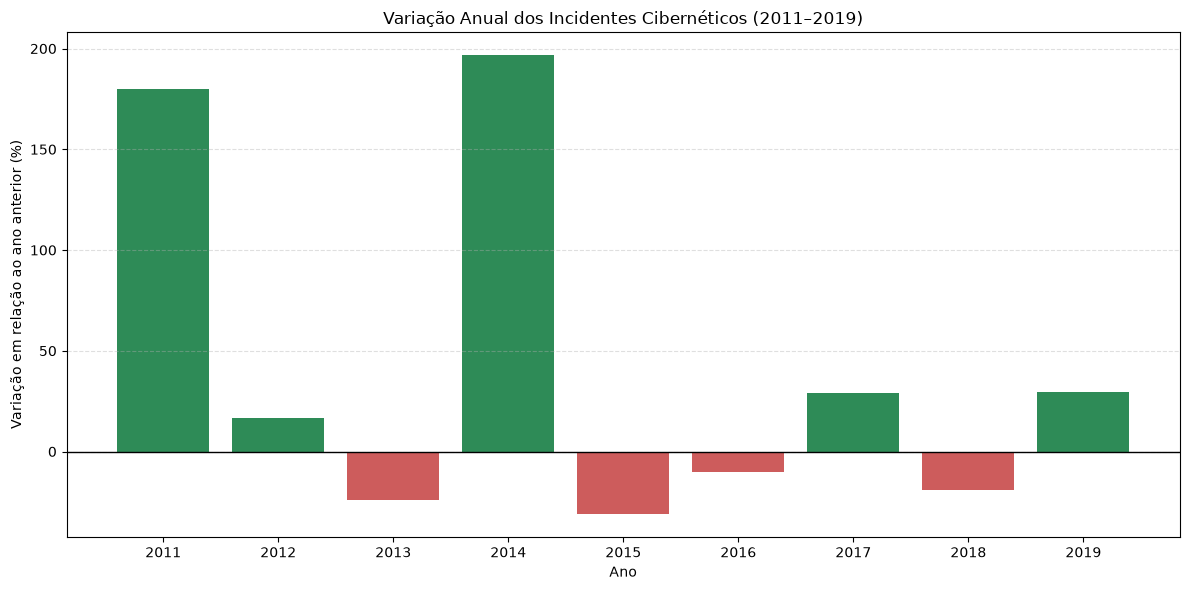

In [6]:
variacao_anual = incidentes_anuais.pct_change() * 100

variacao_anual = variacao_anual.dropna()

print("Variação percentual anual dos incidentes:")
print(variacao_anual.round(2))

print("\nMaior aumento:")
print(f"{variacao_anual.idxmax()}: {variacao_anual.max():.2f}%")

print("\nMaior redução:")
print(f"{variacao_anual.idxmin()}: {variacao_anual.min():.2f}%")

cores = [
    "seagreen" if valor >= 0 else "indianred"
    for valor in variacao_anual.values
]

plt.figure(figsize=(12, 6))

plt.bar(
    variacao_anual.index.astype(str),
    variacao_anual.values,
    color=cores
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Variação Anual dos Incidentes Cibernéticos (2011–2019)")
plt.xlabel("Ano")
plt.ylabel("Variação em relação ao ano anterior (%)")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [7]:
total_geral = incidentes_anuais.sum()
media_anual = incidentes_anuais.mean()
mediana_anual = incidentes_anuais.median()
desvio_padrao = incidentes_anuais.std()

ano_maior = incidentes_anuais.idxmax()
ano_menor = incidentes_anuais.idxmin()

print(f"Total de incidentes: {total_geral:,.0f}")
print(f"Média anual: {media_anual:,.2f}")
print(f"Mediana anual: {mediana_anual:,.2f}")
print(f"Desvio padrão: {desvio_padrao:,.2f}")
print(f"Ano com mais incidentes: {ano_maior}")
print(f"Ano com menos incidentes: {ano_menor}")

Total de incidentes: 6,163,277
Média anual: 616,327.70
Mediana anual: 661,813.00
Desvio padrão: 274,634.02
Ano com mais incidentes: 2014
Ano com menos incidentes: 2010


In [8]:
pasta_graficos = caminho.parent.parent.parent / "docs" / "assets"
pasta_graficos.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(12, 6))
plt.plot(incidentes_anuais.index, incidentes_anuais.values, marker="o", linewidth=2, color="blue")
plt.title("Evolução dos Incidentes Cibernéticos (2010–2019)")
plt.xlabel("Ano")
plt.ylabel("Total de Incidentes")
plt.xticks(incidentes_anuais.index)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(pasta_graficos / "evolucao_anual.png", dpi=300, bbox_inches="tight")
plt.close()

plt.figure(figsize=(12, 6))
sns.barplot(x=total_categorias.index, y=total_categorias.values, color="steelblue")
plt.title("Incidentes Cibernéticos por Categoria (2010–2019)")
plt.xlabel("Categoria")
plt.ylabel("Total de Incidentes")
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(pasta_graficos / "categorias_incidentes.png", dpi=300, bbox_inches="tight")
plt.close()

cores = ["seagreen" if valor >= 0 else "indianred" for valor in variacao_anual.values]

plt.figure(figsize=(12, 6))
plt.bar(variacao_anual.index.astype(str), variacao_anual.values, color=cores)
plt.axhline(0, color="black", linewidth=1)
plt.title("Variação Anual dos Incidentes Cibernéticos (2011–2019)")
plt.xlabel("Ano")
plt.ylabel("Variação em relação ao ano anterior (%)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(pasta_graficos / "variacao_anual.png", dpi=300, bbox_inches="tight")
plt.close()

print("Gráficos exportados com sucesso!")


Gráficos exportados com sucesso!
